In [1]:
%pip install shap xgboost joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [14]:
import os
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib


In [15]:
model = joblib.load("../outputs/models/smartblood_xgboost_model.pkl")

print("Model loaded successfully")
print(type(model))

Model loaded successfully
<class 'xgboost.sklearn.XGBRegressor'>


In [16]:
X_test = pd.read_pickle("../data/processed/X_test.pkl")
y_test = pd.read_pickle("../data/processed/y_test.pkl")

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nFeatures:")
print(X_test.columns.tolist())

display(X_test.head())

X_test shape: (2904, 24)
y_test shape: (2904,)

Features:
['demand', 'demand_lag_1', 'demand_lag_7', 'demand_lag_14', 'demand_lag_30', 'demand_rolling_7', 'demand_rolling_14', 'demand_rolling_30', 'emergency_requests_lag_1', 'target_day_of_week_num', 'target_month', 'target_quarter', 'target_is_weekend', 'blood_group_A+', 'blood_group_A-', 'blood_group_AB+', 'blood_group_AB-', 'blood_group_B+', 'blood_group_B-', 'blood_group_O+', 'blood_group_O-', 'component_Plasma', 'component_Platelets', 'component_RBC']


,demand,demand_lag_1,demand_lag_7,demand_lag_14,demand_lag_30,demand_rolling_7,demand_rolling_14,demand_rolling_30,emergency_requests_lag_1,target_day_of_week_num,...,blood_group_A-,blood_group_AB+,blood_group_AB-,blood_group_B+,blood_group_B-,blood_group_O+,blood_group_O-,component_Plasma,component_Platelets,component_RBC
579,19,38.0,29.0,28.0,31.0,32.428571,32.428571,31.333333,6.0,0,...,0,0,0,0,0,0,0,1,0,0
580,17,19.0,32.0,36.0,28.0,31.000000,31.785714,30.933333,0.0,1,...,0,0,0,0,0,0,0,1,0,0
581,24,17.0,35.0,38.0,32.0,28.857143,30.428571,30.566667,0.0,2,...,0,0,0,0,0,0,0,1,0,0
582,25,24.0,29.0,31.0,33.0,27.285714,29.428571,30.300000,1.0,3,...,0,0,0,0,0,0,0,1,0,0
583,26,25.0,30.0,26.0,33.0,26.714286,29.000000,30.033333,1.0,4,...,0,0,0,0,0,0,0,1,0,0


In [35]:
print("Testing Shape:", X_test.shape)

print("\nFeatures used:")
print(X_test.columns.tolist())

print("\nfirst five test rows:")
display(X_test.head())

Testing Shape: (2904, 24)

Features used:
['demand', 'demand_lag_1', 'demand_lag_7', 'demand_lag_14', 'demand_lag_30', 'demand_rolling_7', 'demand_rolling_14', 'demand_rolling_30', 'emergency_requests_lag_1', 'target_day_of_week_num', 'target_month', 'target_quarter', 'target_is_weekend', 'blood_group_A+', 'blood_group_A-', 'blood_group_AB+', 'blood_group_AB-', 'blood_group_B+', 'blood_group_B-', 'blood_group_O+', 'blood_group_O-', 'component_Plasma', 'component_Platelets', 'component_RBC']

first five test rows:


,demand,demand_lag_1,demand_lag_7,demand_lag_14,demand_lag_30,demand_rolling_7,demand_rolling_14,demand_rolling_30,emergency_requests_lag_1,target_day_of_week_num,...,blood_group_A-,blood_group_AB+,blood_group_AB-,blood_group_B+,blood_group_B-,blood_group_O+,blood_group_O-,component_Plasma,component_Platelets,component_RBC
579,19,38.0,29.0,28.0,31.0,32.428571,32.428571,31.333333,6.0,0,...,0,0,0,0,0,0,0,1,0,0
580,17,19.0,32.0,36.0,28.0,31.000000,31.785714,30.933333,0.0,1,...,0,0,0,0,0,0,0,1,0,0
581,24,17.0,35.0,38.0,32.0,28.857143,30.428571,30.566667,0.0,2,...,0,0,0,0,0,0,0,1,0,0
582,25,24.0,29.0,31.0,33.0,27.285714,29.428571,30.300000,1.0,3,...,0,0,0,0,0,0,0,1,0,0
583,26,25.0,30.0,26.0,33.0,26.714286,29.000000,30.033333,1.0,4,...,0,0,0,0,0,0,0,1,0,0


In [18]:
if hasattr(model, "feature_names_in_"):
    print("Model expects:")
    print(model.feature_names_in_.tolist())

Model expects:
['demand', 'demand_lag_1', 'demand_lag_7', 'demand_lag_14', 'demand_lag_30', 'demand_rolling_7', 'demand_rolling_14', 'demand_rolling_30', 'emergency_requests_lag_1', 'target_day_of_week_num', 'target_month', 'target_quarter', 'target_is_weekend', 'blood_group_A+', 'blood_group_A-', 'blood_group_AB+', 'blood_group_AB-', 'blood_group_B+', 'blood_group_B-', 'blood_group_O+', 'blood_group_O-', 'component_Plasma', 'component_Platelets', 'component_RBC']


In [19]:
X_explain = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

print("Rows selected:", len(X_explain))

Rows selected: 500


In [21]:
explainer = shap.TreeExplainer(model)

shap_values = explainer(X_explain)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (500, 24)


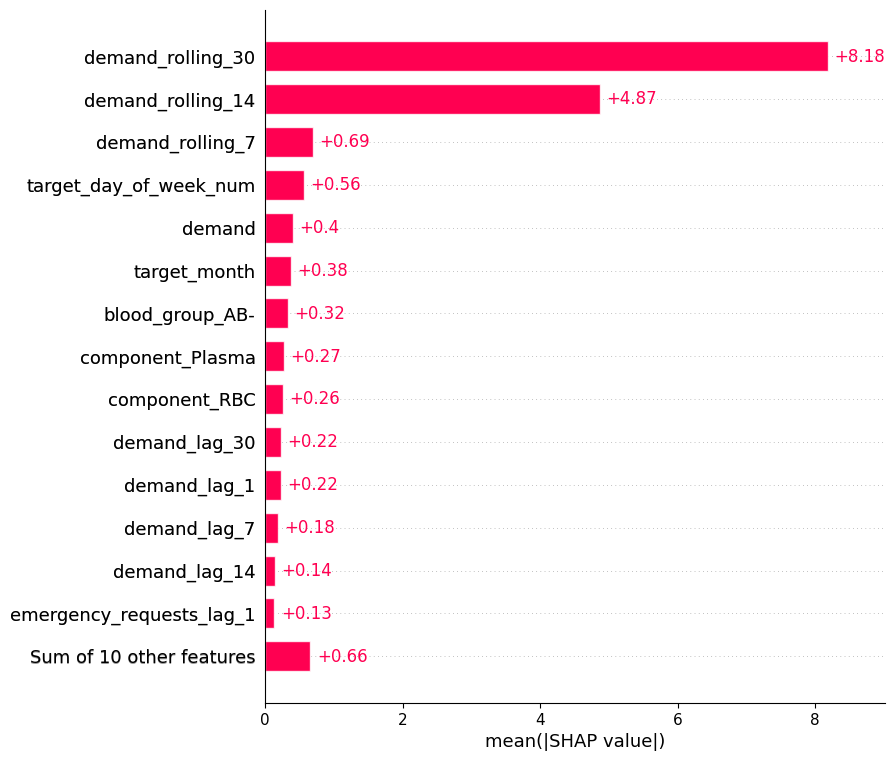

In [22]:
shap.plots.bar(
    shap_values,
    max_display=15
)

plt.show()

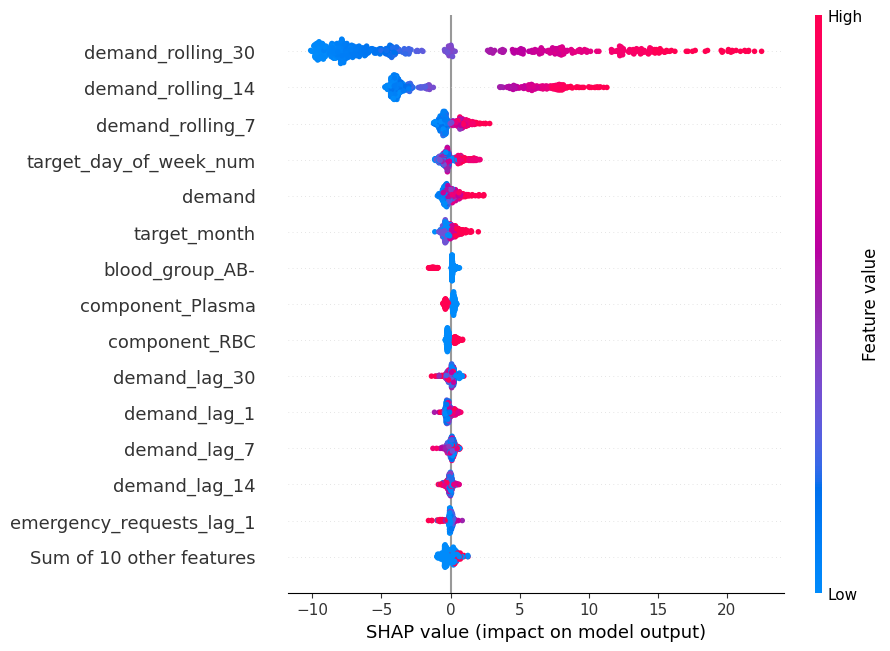

In [36]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

plt.show()

In [23]:
i = 0

display(X_explain.iloc[[i]])

,demand,demand_lag_1,demand_lag_7,demand_lag_14,demand_lag_30,demand_rolling_7,demand_rolling_14,demand_rolling_30,emergency_requests_lag_1,target_day_of_week_num,...,blood_group_A-,blood_group_AB+,blood_group_AB-,blood_group_B+,blood_group_B-,blood_group_O+,blood_group_O-,component_Plasma,component_Platelets,component_RBC
1299,34,30.0,44.0,37.0,31.0,38.428571,37.5,37.5,4.0,6,...,0,0,0,0,0,0,0,0,1,0


In [37]:
predicted_demand = model.predict(
    X_explain.iloc[[i]]
)[0]

print("Predicted demand:", round(float(predicted_demand), 2))

Predicted demand: 38.4


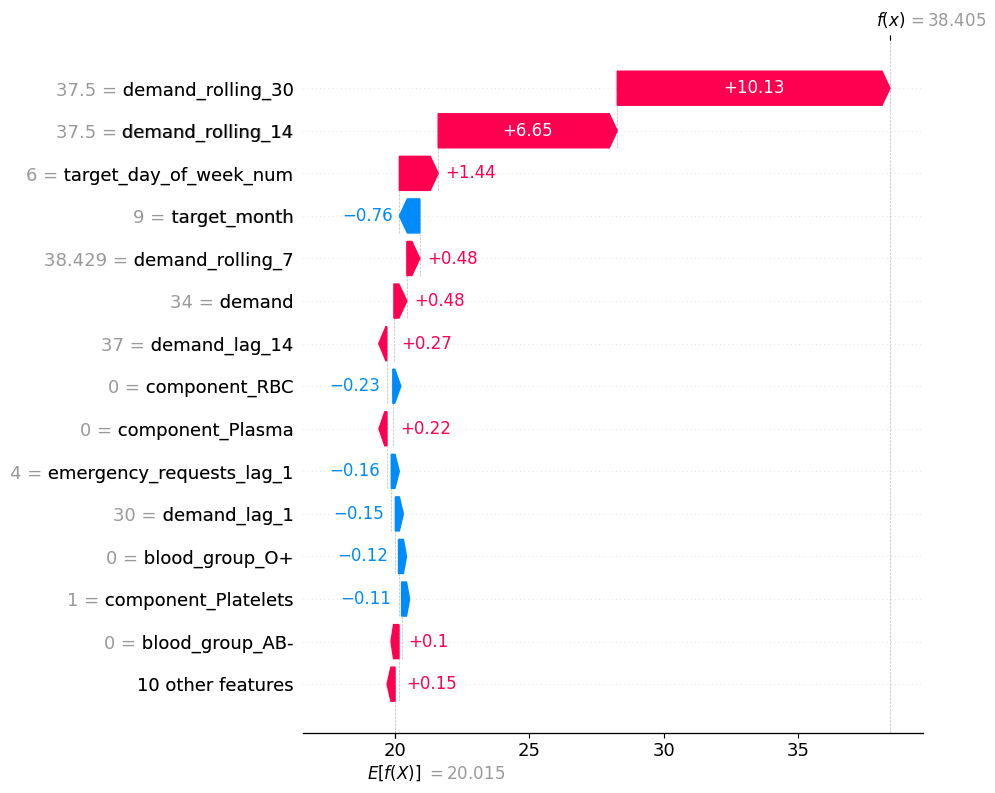

In [26]:
shap.plots.waterfall(
    shap_values[i],
    max_display=15
)

In [27]:
base_value = np.asarray(
    shap_values.base_values
)[i].item()

contributions = np.asarray(
    shap_values.values[i]
)

reconstructed_prediction = (
    base_value + contributions.sum()
)

print("SHAP baseline:", round(float(base_value), 4))
print(
    "Reconstructed prediction:",
    round(float(reconstructed_prediction), 4)
)
print(
    "Model prediction:",
    round(float(predicted_demand), 4)
)

SHAP baseline: 20.015
Reconstructed prediction: 38.4046
Model prediction: 38.4046


In [28]:
from pathlib import Path

output_dir = Path("../reports/shap")
output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder:", output_dir.resolve())

Output folder: C:\Users\Ankit Sharma\FinalYear_project\SmartBlood\reports\shap


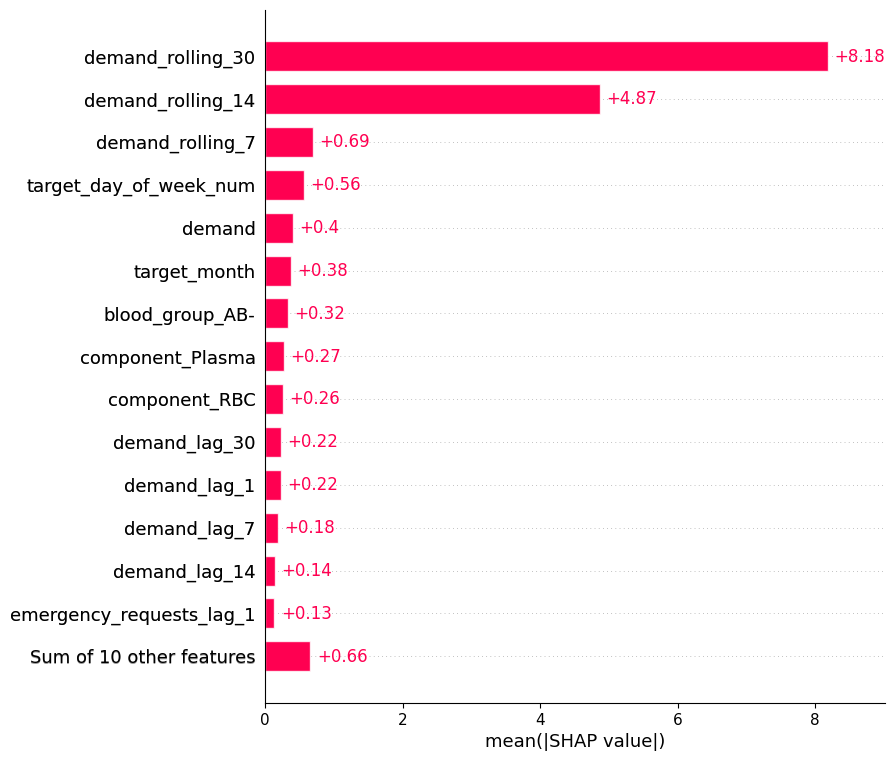

In [29]:
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.gcf().savefig(
    output_dir / "global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close("all")

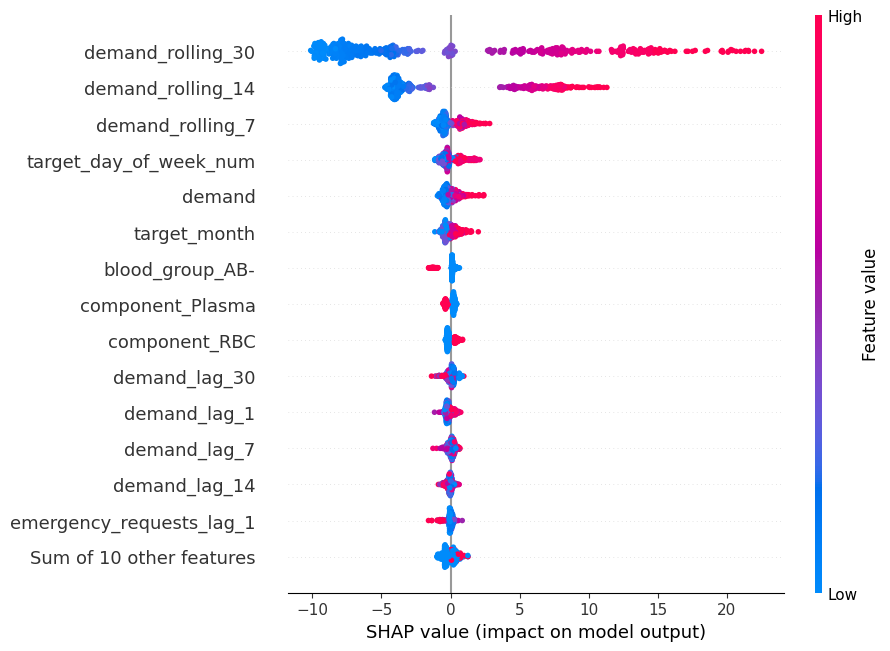

In [30]:
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.gcf().savefig(
    output_dir / "global_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close("all")

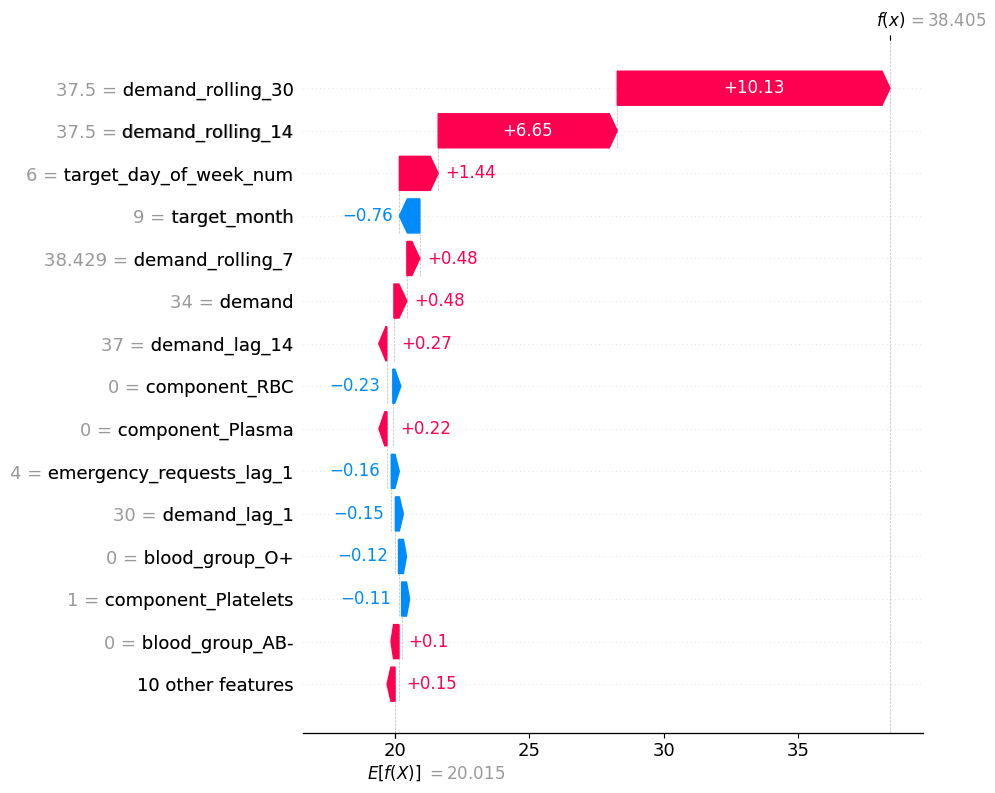

In [31]:
shap.plots.waterfall(
    shap_values[i],
    max_display=15,
    show=False
)

plt.gcf().savefig(
    output_dir / "local_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close("all")

In [32]:
importance_df = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_absolute_shap": np.abs(
        shap_values.values
    ).mean(axis=0)
})

importance_df = importance_df.sort_values(
    "mean_absolute_shap",
    ascending=False
)

display(importance_df)

importance_df.to_csv(
    output_dir / "global_shap_importance.csv",
    index=False
)

,feature,mean_absolute_shap
7,demand_rolling_30,8.180213
6,demand_rolling_14,4.867123
5,demand_rolling_7,0.693057
9,target_day_of_week_num,0.560105
0,demand,0.404393
10,target_month,0.375475
16,blood_group_AB-,0.324945
21,component_Plasma,0.266169
23,component_RBC,0.255743
4,demand_lag_30,0.224832


In [33]:
local_df = pd.DataFrame({
    "feature": X_explain.columns,
    "feature_value": X_explain.iloc[i].values,
    "shap_value": shap_values.values[i]
})

local_df["absolute_shap"] = local_df["shap_value"].abs()

local_df = local_df.sort_values(
    "absolute_shap",
    ascending=False
)

display(local_df)

local_df.to_csv(
    output_dir / "local_shap_explanation.csv",
    index=False
)

,feature,feature_value,shap_value,absolute_shap
7,demand_rolling_30,37.500000,10.133456,10.133456
6,demand_rolling_14,37.500000,6.653527,6.653527
9,target_day_of_week_num,6.000000,1.442235,1.442235
10,target_month,9.000000,-0.760215,0.760215
5,demand_rolling_7,38.428571,0.481404,0.481404
0,demand,34.000000,0.481013,0.481013
3,demand_lag_14,37.000000,0.266248,0.266248
23,component_RBC,0.000000,-0.225151,0.225151
21,component_Plasma,0.000000,0.218324,0.218324
8,emergency_requests_lag_1,4.000000,-0.161636,0.161636
